# 🔴 Implement for T1 (some codes are common)

## ⚪ 1. Libraries

In [1]:
import pandas as pd
import scipy.io
import numpy as np
from scipy.io import loadmat
from sklearn.preprocessing import MinMaxScaler
from scipy.spatial.distance import cdist
from sklearn.metrics import roc_auc_score, average_precision_score
import matplotlib.pyplot as plt

## ⚪ 2. Extract indices from .csv file

In [2]:
# Define the path to your CSV file.
csv_file_path = 'thyroidori.csv'

In [5]:
# --- Configuration ---
try:
    # --- Step 1: Load the original (raw) dataset using pandas ---
    df_original = pd.read_csv(csv_file_path, header=None) #, header=None
    print(f"Shape of the original dataset: {df_original.shape} (rows, columns)")

    num_cols = df_original.shape[1]

    # For better readability, let's assign names to the columns.
    column_names = [f"c{i}" for i in range(1, num_cols)] + ["label"]
    df_original.columns = column_names

    # --- Step 2: Apply the condition to define the T1 subset ---
    condition = (df_original['c2'] >= 0) & (df_original['c2'] <= 0.5)

    # Create the T1 subset dataframe by applying the filter
    df_t1 = df_original[condition]

    # --- Step 3: Extract the indices of the rows that satisfy the condition ---
    t1_indices = df_t1.index.to_numpy()

    # --- Step 4" Checking the Number of Outliers in T1 ---
    t1_label_counts = df_t1['label'].value_counts()

    # --- Output and Verification ---
    print(f"Number of samples satisfying the T1 condition: {len(t1_indices)}")

    # Display the number of outliers in T1.
    print(f"Number of outliers in the T1 subset: {t1_label_counts}")

except Exception as e:
    print(f"An unexpected error occurred: {e}")

Shape of the original dataset: (3772, 7) (rows, columns)
Number of samples satisfying the T1 condition: 3766
Number of outliers in the T1 subset: label
1    3679
2      87
Name: count, dtype: int64


## ⚪ 3. Making X_tem from T1 indices italicized text

In [6]:
print("Shape of T1: ", t1_indices.shape, )
print()
print("index of T1 :", t1_indices)
print()
print("type of T1: ", type(t1_indices))

Shape of T1:  (3766,)

index of T1 : [   0    1    2 ... 3769 3770 3771]

type of T1:  <class 'numpy.ndarray'>


In [7]:
# Conver t1_indices to python list
X_tem1 = t1_indices.tolist()

## ⚪ 4. Checking .mat file

In [8]:
mat = scipy.io.loadmat('thyroid.mat')
print(mat.keys())
print(pd.DataFrame(mat['trandata']).describe())

# mat['trandata']

dict_keys(['__header__', '__version__', '__globals__', 'trandata'])
                 0            1            2            3            4  \
count  3772.000000  3772.000000  3772.000000  3772.000000  3772.000000   
mean      0.543121     0.008983     0.186826     0.248332     0.376941   
std       0.203790     0.043978     0.070405     0.080579     0.087382   
min       0.000000     0.000000     0.000000     0.000000     0.000000   
25%       0.376344     0.001132     0.156546     0.203271     0.328638   
50%       0.569892     0.003019     0.190702     0.241822     0.375587   
75%       0.709677     0.004528     0.213472     0.282710     0.413146   
max       1.000000     1.000000     1.000000     1.000000     1.000000   

                 5            6  
count  3772.000000  3772.000000  
mean      0.177301     0.024655  
std       0.054907     0.155093  
min       0.000000     0.000000  
25%       0.149180     0.000000  
50%       0.173770     0.000000  
75%       0.196721     0.00

In [9]:
pd.DataFrame(mat['trandata']).head()

,0,1,2,3,4,5,6
0,0.774194,0.001132,0.137571,0.275701,0.295775,0.236066,0.0
1,0.247312,0.000472,0.279886,0.329439,0.535211,0.173770,0.0
2,0.494624,0.003585,0.222960,0.233645,0.525822,0.124590,0.0
3,0.677419,0.001698,0.156546,0.175234,0.333333,0.136066,0.0
4,0.236559,0.000472,0.241935,0.320093,0.333333,0.247541,0.0


## ⚪ 5. Main code of 3WNCROD

In [10]:
def WNCROD(data, X_tem, lammda):

    n, m = data.shape
    X = np.zeros(n)
    X[X_tem] = 1

    D1 = m / 3
    D2 = m / 2
    D3 = 0.9 * m

    delta = np.zeros(m)
    ID = np.all(data <= 1, axis=0)
    delta[ID] = np.std(data[:, ID], axis=0) / lammda

    Lower = np.zeros((m, n))

    for col in range(m):
        RM_tem = cdist(data[:, [col]], data[:, [col]], metric='cityblock') <= delta[col]
        Lower_temp = np.min(np.maximum(1 - RM_tem, np.tile(X, (n, 1))), axis=1)
        Lower[col, :Lower_temp.shape[0]] = Lower_temp

    IB = np.tile(X, (m, 1)) - Lower
    NEB = np.min(IB, axis=0)
    NPB = IB - np.tile(NEB, (m, 1))

    n_X = int(sum(X))

    weight = np.zeros((n_X, m))

    for col in range(m):
        RM_tem = cdist(data[:, [col]], data[:, [col]], metric='cityblock') <= delta[col]
        weight_x = []

        for i in range(n_X):
            temp1 = RM_tem[X_tem[i], :]
            weight_temp = 1 - (np.sqrt((np.sum(np.minimum(temp1, X))) / n_X))
            weight_x.append(weight_temp)

        weight[:len(weight_x), col] = weight_x

    D_tem = np.zeros((n, n))

    for col in range(m):
        RM_tem = cdist(data[:, [col]], data[:, [col]], metric='cityblock') <= delta[col]
        D_tem += RM_tem

    NOM = m - D_tem
    X_OM = NOM[np.ix_(X_tem, X_tem)]

    NEB_num = np.zeros((n_X, m))
    Lower_num = np.zeros((n_X, m))
    NPB_num = np.zeros((n_X, m))

    for col in range(m):
        temp2 = Lower[col, :]
        temp3 = NPB[col, :]

        for i in range(n_X):
            temp1 = X_OM[i, :]
            NEB_num[i, col] = np.sum(np.minimum(NEB[X_tem], temp1 <= D1))
            NPB_num[i, col] = np.sum(np.minimum(temp3[X_tem], temp1 >= D2))
            Lower_num[i, col] = np.sum(np.minimum(temp2[X_tem], temp1 >= D3))

    MNOF = np.mean(((NEB_num + Lower_num + NPB_num) / n_X) * weight, axis=1)
    return MNOF


## ⚪ 6. Run algorythm for T1

In [17]:
if __name__ == "__main__":

    # 1) Load data
    mat       = loadmat('thyroid.mat')
    full_data = mat['trandata']            # shape = (n_samples, 7)

    # 2) Separate features and labels
    X1 = full_data[:, :6]                   # First 6 columns
    y1 =  full_data[:, 6].astype(int)       # Column 7 (index 6)

    # 3) Normalize only the features (columns 0, 1, 2, 3, 4, 5)
    scaler = MinMaxScaler()
    # بردار ستون‌های عددی را جدا می‌کنیم و نرمال می‌کنیم
    X1[:, 1:] = scaler.fit_transform(X1[:, 1:])

    # 4) Run the algorithm with the same X_tem and lammda=0.1
    out_scores = WNCROD(X1, X_tem1, lammda=0.1)

    # 5) Extract true labels only for X_tem1
    y_true = y1[X_tem1]

    # 6) Compute metrics
    roc_auc1 = roc_auc_score(y_true, out_scores)
    ap1      = average_precision_score(y_true, out_scores)

    print(f"ROC-AUC: {roc_auc1:.4f}")
    print(f"Average Precision (AP): {ap1:.4f}")

ROC-AUC: 0.9848
Average Precision (AP): 0.6701


In [18]:
if __name__ == "__main__":

    # 0) لیست 10 مقدار λ که می‌خواهید تست کنید
    lambda_list = [0.1, 0.2, 0.3, 0.4, 0.5,
                   0.6, 0.7, 0.8, 0.9, 1.0,
                   1.1, 1.2, 1.3, 1.4, 1.5,
                   1.6, 1.7, 1.8, 1.9, 2.0,
                   2.1, 2.2, 2.3, 2.4, 2.5]

    # 1) Load data
    mat       = loadmat('thyroid.mat')
    full_data = mat['trandata']            # shape = (n_samples, 21)

    # 2) Separate features and labels
    X1 = full_data[:, :6]                   # First 20 columns
    y1 = full_data[:, 6].astype(int)        # Column 21 (index 20)

    # 3) Normalize only the features
    scaler = MinMaxScaler()
    # بردار ستون‌های عددی را جدا می‌کنیم و نرمال می‌کنیم
    X1[:, 1:] = scaler.fit_transform(X1[:, 1:])

    # 4) True labels for t1 (فرض بر این است که X_tem از قبل تعریف شده)
    y_true = y1[X_tem1]

    # 5) حلقه روی همه λها و محاسبهٔ خروجیt1 معیارها
    results = []
    for lam in lambda_list:
        out_scores = WNCROD(X1, X_tem1, lammda=lam)

        # محاسبهٔ معیارها
        roc_auc = roc_auc_score(y_true, out_scores)
        ap      =average_precision_score(y_true, out_scores)

        results.append({
            'lambda': lam,
            'ROC-AUC': roc_auc,
            'AP': ap
        })

    # 6)t1مایش نتایج
    for r in results:
        print(f"λ = {r['lambda']:.1f} | ROC-AUC = {r['ROC-AUC']:.4f} | AP = {r['AP']:.4f}")

λ = 0.1 | ROC-AUC = 0.9848 | AP = 0.6701
λ = 0.2 | ROC-AUC = 0.9171 | AP = 0.2111
λ = 0.3 | ROC-AUC = 0.8837 | AP = 0.1459
λ = 0.4 | ROC-AUC = 0.8750 | AP = 0.1524
λ = 0.5 | ROC-AUC = 0.8930 | AP = 0.1632
λ = 0.6 | ROC-AUC = 0.9197 | AP = 0.1630
λ = 0.7 | ROC-AUC = 0.9278 | AP = 0.1672
λ = 0.8 | ROC-AUC = 0.9306 | AP = 0.1692
λ = 0.9 | ROC-AUC = 0.9339 | AP = 0.1846
λ = 1.0 | ROC-AUC = 0.9401 | AP = 0.2438
λ = 1.1 | ROC-AUC = 0.9450 | AP = 0.3382
λ = 1.2 | ROC-AUC = 0.9494 | AP = 0.4012
λ = 1.3 | ROC-AUC = 0.9561 | AP = 0.4826
λ = 1.4 | ROC-AUC = 0.9606 | AP = 0.5468
λ = 1.5 | ROC-AUC = 0.9661 | AP = 0.6182
λ = 1.6 | ROC-AUC = 0.9694 | AP = 0.6457
λ = 1.7 | ROC-AUC = 0.9716 | AP = 0.6837
λ = 1.8 | ROC-AUC = 0.9723 | AP = 0.6861
λ = 1.9 | ROC-AUC = 0.9747 | AP = 0.7116
λ = 2.0 | ROC-AUC = 0.9764 | AP = 0.7159
λ = 2.1 | ROC-AUC = 0.9770 | AP = 0.7275
λ = 2.2 | ROC-AUC = 0.9770 | AP = 0.7330
λ = 2.3 | ROC-AUC = 0.9783 | AP = 0.7303
λ = 2.4 | ROC-AUC = 0.9804 | AP = 0.7369
λ = 2.5 | ROC-AU

In [ ]:
# لیست λها و مقادیر متناظر ROC-AUC
lambda_list = [0.0, 0.0, 0.0, 0.0, 0.0
               0.0, 0.0, 0.0, 0.0, 0.0]

roc_auc_list = [0.0357, 0.0357, 0.0357, 0.9799, 0.9823,
                0.9859, 0.9844, 0.9831, 0.9818, 0.9776,
                0.9769, 0.9872, 0.9874, 0.9872, 0.9868,
                0.9868, 0.9865, 0.9863, 0.9865, 0.9865]

# رسم نمودار
plt.figure(figsize=(8, 5))
plt.plot(lambda_list, roc_auc_list, marker='o', linestyle='-',
         color='C0', label='ROC-AUC')
plt.title('ROC-AUC vs λ (A1)')
plt.xlabel('λ')
plt.ylabel('ROC-AUC')
plt.xticks(lambda_list, rotation=45)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## ⚪ 7. Radius Neighborhood for T1

In [ ]:
    n, m = X1.shape
    lammda = 2.0
    delta = np.zeros(m)
    ID = np.all(X1 <= 1, axis=0)
    delta[ID] = np.std(X1[:, ID], axis=0) / lammda

    print(f"Neighborhood radius for each {X1.shape[1]} Features with λ = {lammda} for T1:")
    for idx, d in enumerate(delta, start=1):
        print(f"  Feature : {idx:2d}: δ(Neighborhood radius ) = {d:.6f}")

Neighborhood radius for each 20 Features with λ = 2.0 for G1:
  Feature :  1: δ(Neighborhood radius ) = 0.000000
  Feature :  2: δ(Neighborhood radius ) = 0.102455
  Feature :  3: δ(Neighborhood radius ) = 0.000000
  Feature :  4: δ(Neighborhood radius ) = 0.000000
  Feature :  5: δ(Neighborhood radius ) = 0.071423
  Feature :  6: δ(Neighborhood radius ) = 0.000000
  Feature :  7: δ(Neighborhood radius ) = 0.000000
  Feature :  8: δ(Neighborhood radius ) = 0.188049
  Feature :  9: δ(Neighborhood radius ) = 0.000000
  Feature : 10: δ(Neighborhood radius ) = 0.000000
  Feature : 11: δ(Neighborhood radius ) = 0.184636
  Feature : 12: δ(Neighborhood radius ) = 0.000000
  Feature : 13: δ(Neighborhood radius ) = 0.103085
  Feature : 14: δ(Neighborhood radius ) = 0.000000
  Feature : 15: δ(Neighborhood radius ) = 0.000000
  Feature : 16: δ(Neighborhood radius ) = 0.098027
  Feature : 17: δ(Neighborhood radius ) = 0.000000
  Feature : 18: δ(Neighborhood radius ) = 0.183147
  Feature : 19: δ(Ne

# 🔴 Implement for T2

## ⚪ 2. Extract indices from .csv file

In [19]:
# --- Configuration ---
try:
    # --- Step 1: Load the original (raw) dataset using pandas ---
    # df_original = pd.read_csv(csv_file_path, header=None)
    print(f"Shape of the original dataset: {df_original.shape} (rows, columns)")

    num_cols = df_original.shape[1]

    # For better readability, let's assign names to the columns.
    column_names = [f"c{i}" for i in range(1, num_cols)] + ["label"]
    df_original.columns = column_names

    # --- Step 2: Apply the condition2 to define the t2 subset ---
    condition2 = (df_original['c6'] >= 0) & (df_original['c6'] <= 0.3)

    # Create the t2 subset dataframe by applying the filter
    df_t2 = df_original[condition2]

    # --- Step 3: Extract the indices of the rows that satisfy the condition ---
    t2_indices = df_t2.index.to_numpy()

    # --- Step 4" Checking the Number of Outliers in t2 ---
    t2_label_counts = df_t2['label'].value_counts()

    # --- Output and Verification ---
    print(f"Number of samples satisfying the t2 condition: {len(t2_indices)}")

    # Display the number of outliers in t2.
    print(f"Number of outliers in the t2 subset: {t2_label_counts}")

except Exception as e:
    print(f"An unexpected error occurred: {e}")

Shape of the original dataset: (3772, 7) (rows, columns)
Number of samples satisfying the t2 condition: 3676
Number of outliers in the t2 subset: label
1    3583
2      93
Name: count, dtype: int64


## ⚪ 3. Making X_tem from t2 indices italicized text

In [20]:
# Conver a2_indices to python list
X_tem2 = t2_indices.tolist()

## ⚪ 6. Run algorythm for t2

In [23]:
if __name__ == "__main__":

    # 1) Load data
    mat       = loadmat('thyroid.mat')
    full_data = mat['trandata']            # shape = (n_samples, 7)

    # 2) Separate features and labels
    X2 = full_data[:, :6]                   # First 6 columns
    y2 =  full_data[:, 6].astype(int)       # Column 7 (index 6)

    # 3) Normalize only the features
    scaler = MinMaxScaler()
    # بردار ستون‌های عددی را جدا می‌کنیم و نرمال می‌کنیم
    X2[:, 1:] = scaler.fit_transform(X2[:, 1:])

    # 4) Run the algorithm with the same X_tem2 and lammda=2.0
    out_scores2 = WNCROD(X2, X_tem2, lammda=2.0)

    # 5) Extract true labels only for X_tem2
    y_true2 = y2[X_tem2]

    # 6) Compute metrics
    roc_auc_t2 = roc_auc_score(y_true2, out_scores2)
    ap_t2      = average_precision_score(y_true2, out_scores2)

    print(f"ROC-AUC: {roc_auc_t2:.4f}")
    print(f"Average Precision (AP): {ap_t2:.4f}")

ROC-AUC: 0.9846
Average Precision (AP): 0.7610


In [25]:
if __name__ == "__main__":
    # لیست λهایی که می‌خواهید تست کنید
    lambda_list = [0.1, 0.2, 0.3, 0.4, 0.5,
                   0.6, 0.7, 0.8, 0.9, 1.0,
                   1.1, 1.2, 1.3, 1.4, 1.5,
                   1.6, 1.7, 1.8, 1.9, 2.0,
                   2.1, 2.2, 2.3, 2.4, 2.5]

    # 1) بارگذاری داده
    mat       = loadmat('thyroid.mat')
    full_data = mat['trandata']            # شکل: (n_samples, 7)

    # 2) جدا کردن ویژگی‌ها و برچسب‌ها
    X2 = full_data[:, :6]                  # 6 ستون اول
    y2 = full_data[:, 6].astype(int)       # ستون 7 (اندیس 6)

    # 3) Normalize only the features
    scaler = MinMaxScaler()
    # بردار ستون‌های عددی را جدا می‌کنیم و نرمال می‌کنیم
    X2[:, 1:] = scaler.fit_transform(X2[:, 1:])

    # 4) برچسب‌های واقعی برای نمونه‌های X_tem2
    y_true2 = y2[X_tem2]

    # 5) حلقه برای اجرای WNCROD با مقادیر مختلف λ و محاسبه معیارها
    results2 = []
    for lam in lambda_list:
        out_scores2 = WNCROD(X2, X_tem2, lammda=lam)
        roc2 = roc_auc_score(y_true2, out_scores2)
        ap2  = average_precision_score(y_true2, out_scores2)
        results2.append({
            'lambda': lam,
            'ROC-AUC': roc2,
            'AP': ap2
        })

    # 6) نمایش نتایج
    print("نتایج t2 برای λهای مختلف:")
    for r in results2:
        print(f"λ = {r['lambda']:.1f} | ROC-AUC = {r['ROC-AUC']:.4f} | AP = {r['AP']:.4f}")

نتایج t2 برای λهای مختلف:
λ = 0.1 | ROC-AUC = 0.1533 | AP = 0.0973
λ = 0.2 | ROC-AUC = 0.8280 | AP = 0.3278
λ = 0.3 | ROC-AUC = 0.9309 | AP = 0.2972
λ = 0.4 | ROC-AUC = 0.9188 | AP = 0.1635
λ = 0.5 | ROC-AUC = 0.9223 | AP = 0.2606
λ = 0.6 | ROC-AUC = 0.9482 | AP = 0.3708
λ = 0.7 | ROC-AUC = 0.9631 | AP = 0.4439
λ = 0.8 | ROC-AUC = 0.9669 | AP = 0.4839
λ = 0.9 | ROC-AUC = 0.9700 | AP = 0.5146
λ = 1.0 | ROC-AUC = 0.9728 | AP = 0.5643
λ = 1.1 | ROC-AUC = 0.9750 | AP = 0.6177
λ = 1.2 | ROC-AUC = 0.9771 | AP = 0.6501
λ = 1.3 | ROC-AUC = 0.9789 | AP = 0.6783
λ = 1.4 | ROC-AUC = 0.9806 | AP = 0.7061
λ = 1.5 | ROC-AUC = 0.9825 | AP = 0.7217
λ = 1.6 | ROC-AUC = 0.9833 | AP = 0.7357
λ = 1.7 | ROC-AUC = 0.9838 | AP = 0.7528
λ = 1.8 | ROC-AUC = 0.9837 | AP = 0.7486
λ = 1.9 | ROC-AUC = 0.9842 | AP = 0.7610
λ = 2.0 | ROC-AUC = 0.9846 | AP = 0.7610
λ = 2.1 | ROC-AUC = 0.9846 | AP = 0.7696
λ = 2.2 | ROC-AUC = 0.9844 | AP = 0.7776
λ = 2.3 | ROC-AUC = 0.9846 | AP = 0.7766
λ = 2.4 | ROC-AUC = 0.9857 | AP

## ⚪ 7. Radius Neighborhood for t2

In [26]:
    n, m = X2.shape
    lammda = 2.0
    delta = np.zeros(m)
    ID = np.all(X2 <= 1, axis=0)
    delta[ID] = np.std(X2[:, ID], axis=0) / lammda

    print(f"Neighborhood radius for each {X2.shape[1]} Features with λ = {lammda} for t2:")
    for idx, d in enumerate(delta, start=1):
        print(f"  Feature : {idx:2d}: δ(Neighborhood radius ) = {d:.6f}")

Neighborhood radius for each 6 Features with λ = 2.0 for t2:
  Feature :  1: δ(Neighborhood radius ) = 0.101882
  Feature :  2: δ(Neighborhood radius ) = 0.021986
  Feature :  3: δ(Neighborhood radius ) = 0.035198
  Feature :  4: δ(Neighborhood radius ) = 0.040284
  Feature :  5: δ(Neighborhood radius ) = 0.043685
  Feature :  6: δ(Neighborhood radius ) = 0.027450


# 🔴 Implement for t3

## ⚪ 2. Extract indices from .csv file

In [27]:
# --- Configuration ---
try:
    # --- Step 1: Load the original (raw) dataset using pandas ---
    # df_original = pd.read_csv(csv_file_path, header=None)
    print(f"Shape of the original dataset: {df_original.shape} (rows, columns)")
    num_cols = df_original.shape[1]

    # For better readability, let's assign names to the columns.
    column_names = [f"c{i}" for i in range(1, num_cols)] + ["label"]
    df_original.columns = column_names

    # --- Step 2: Apply the condition3 to define the t3 subset ---
    condition3 = (df_original['c5'] >= 0) & (df_original['c5'] <= 0.5)

    # Create the t3 subset dataframe by applying the filter
    df_t3 = df_original[condition3]

    # --- Step 3: Extract the indices of the rows that satisfy the condition ---
    t3_indices = df_t3.index.to_numpy()

    # --- Step 4" Checking the Number of Outliers in t3 ---
    t3_label_counts = df_t3['label'].value_counts()

    # --- Output and Verification ---
    print(f"t3 Condition: Feature 'c5' must be in the range [0, 0.5].")
    print(f"Total number of samples in the original dataset: {len(df_original)}")
    print(f"Number of samples satisfying the t3 condition: {len(t3_indices)}")

    # Display the first few indices for a quick check.
    print(f"First 10 indices of the t3 subset: {t3_indices[:10]}")

    # Display the number of outliers in t3.
    print(f"Number of outliers in the t3 subset: {t3_label_counts}")

except Exception as e:
    print(f"An unexpected error occurred: {e}")

Shape of the original dataset: (3772, 7) (rows, columns)
t3 Condition: Feature 'c6' must be in the range [-1, 1].
Total number of samples in the original dataset: 3772
Number of samples satisfying the t3 condition: 3530
First 10 indices of the t3 subset: [ 0  3  4  5  6  7  8 10 11 12]
Number of outliers in the t3 subset: label
1    3447
2      83
Name: count, dtype: int64


## ⚪ 3. Making X_tem from T3 indices italicized text

In [28]:
# Conver t3_indices to python list
X_tem3 = t3_indices.tolist()

## ⚪ 6. Run algorythm for T3

In [29]:
if __name__ == "__main__":

    # 1) Load data
    mat       = loadmat('thyroid.mat')
    full_data = mat['trandata']            # shape = (n_samples, 7)

    # 2) Separate features and labels
    X3 = full_data[:, :6]                   # First 6 columns
    y3 =  full_data[:, 6].astype(int)       # Column 7 (index 6)

    # 3) Normalize only the features
    scaler = MinMaxScaler()
    # بردار ستون‌های عددی را جدا می‌کنیم و نرمال می‌کنیم
    X3[:, 1:] = scaler.fit_transform(X3[:, 1:])

    # 4) Run the algorithm with the same X_tem3 and lammda=2.0
    out_scores3 = WNCROD(X3, X_tem3, lammda=2.0)

    # 5) Extract true labels only for X_tem3
    y_true3 = y3[X_tem3]

    # 6) Compute metrics
    roc_auc_t3 = roc_auc_score(y_true3, out_scores3)
    ap_t3      = average_precision_score(y_true3, out_scores3)

    print(f"ROC-AUC: {roc_auc_t3:.4f}")
    print(f"Average Precision (AP): {ap_t3:.4f}")

ROC-AUC: 0.9924
Average Precision (AP): 0.8518


In [30]:

if __name__ == "__main__":
    # 1) مقادیر λ که می‌خواهید تست کنید
    lambda_list = [0.1, 0.2, 0.3, 0.4, 0.5,
                   0.6, 0.7, 0.8, 0.9, 1.0,
                   1.1, 1.2, 1.3, 1.4, 1.5,
                   1.6, 1.7, 1.8, 1.9, 2.0,
                   2.1, 2.2, 2.3, 2.4, 2.5]

    # 2) بارگذاری داده
    mat       = loadmat('thyroid.mat')
    full_data = mat['trandata']            # shape = (n_samples, 7)

    # 3) Separate features and labels
    X3 = full_data[:, :6]                   # First 6 columns
    y3 =  full_data[:, 6].astype(int)       # Column 7 (index 6)

    # 3) Normalize only the features
    scaler = MinMaxScaler()
    # بردار ستون‌های عددی را جدا می‌کنیم و نرمال می‌کنیم
    X3[:, 1:] = scaler.fit_transform(X3[:, 1:])

    # 5) استخراج برچسب‌های واقعی برای X_tem3
    y_true3 = y3[X_tem3]

    # 6) اجرای حلقه برای همه λها و محاسبهٔ معیارها
    results3 = []
    for lam in lambda_list:
        out_scores3 = WNCROD(X3, X_tem3, lammda=lam)
        roc3 = roc_auc_score(y_true3, out_scores3)
        ap3  = average_precision_score(y_true3, out_scores3)
        results3.append({
            'lambda': lam,
            'ROC-AUC': roc3,
            'AP': ap3
        })

    # 7) نمایش نتایج
    print("نتایج t3 برای λهای مختلف:")
    for r in results3:
        print(f"λ = {r['lambda']:.1f} | ROC-AUC = {r['ROC-AUC']:.4f} | AP = {r['AP']:.4f}")



نتایج t3 برای λهای مختلف:
λ = 0.1 | ROC-AUC = 0.9737 | AP = 0.5983
λ = 0.2 | ROC-AUC = 0.9747 | AP = 0.3838
λ = 0.3 | ROC-AUC = 0.9590 | AP = 0.3359
λ = 0.4 | ROC-AUC = 0.9372 | AP = 0.2343
λ = 0.5 | ROC-AUC = 0.9355 | AP = 0.1885
λ = 0.6 | ROC-AUC = 0.9545 | AP = 0.4217
λ = 0.7 | ROC-AUC = 0.9741 | AP = 0.5871
λ = 0.8 | ROC-AUC = 0.9780 | AP = 0.6413
λ = 0.9 | ROC-AUC = 0.9812 | AP = 0.6762
λ = 1.0 | ROC-AUC = 0.9833 | AP = 0.6900
λ = 1.1 | ROC-AUC = 0.9851 | AP = 0.7280
λ = 1.2 | ROC-AUC = 0.9870 | AP = 0.7594
λ = 1.3 | ROC-AUC = 0.9883 | AP = 0.7825
λ = 1.4 | ROC-AUC = 0.9897 | AP = 0.8008
λ = 1.5 | ROC-AUC = 0.9913 | AP = 0.8178
λ = 1.6 | ROC-AUC = 0.9918 | AP = 0.8284
λ = 1.7 | ROC-AUC = 0.9919 | AP = 0.8361
λ = 1.8 | ROC-AUC = 0.9920 | AP = 0.8401
λ = 1.9 | ROC-AUC = 0.9924 | AP = 0.8493
λ = 2.0 | ROC-AUC = 0.9924 | AP = 0.8518
λ = 2.1 | ROC-AUC = 0.9923 | AP = 0.8574
λ = 2.2 | ROC-AUC = 0.9921 | AP = 0.8568
λ = 2.3 | ROC-AUC = 0.9924 | AP = 0.8552
λ = 2.4 | ROC-AUC = 0.9926 | AP

# 🟢 Final plot

In [ ]:
# بازه مشترک λ برای هر سه A
lambda_list = [0.1, 0.2, 0.3, 0.4, 0.5,
               0.6, 0.7, 0.8, 0.9, 1.0,
               1.1, 1.2, 1.3, 1.4, 1.5,
               1.6, 1.7, 1.8, 1.9, 2.0]

# مقادیر ROC-AUC برای هر A
roc_auc_t1 =  [0.0357, 0.0357, 0.0357, 0.9799, 0.9823,
               0.9859, 0.9844, 0.9831, 0.9818, 0.9776,
               0.9769, 0.9872, 0.9874, 0.9872, 0.9868,
               0.9868, 0.9865, 0.9863, 0.9865, 0.9865]

roc_auc_t2 = [0.9464, 0.9630, 0.9770, 0.9821, 0.9849,
              0.9863, 0.9857, 0.9849, 0.9834, 0.9802,
              0.9791, 0.9836, 0.9842, 0.9842, 0.9832,
              0.9829, 0.9830, 0.9830, 0.9832, 0.9822]

roc_auc_t3 = [0.9254, 0.9814, 0.9873, 0.9962, 0.9941,
              0.9958, 0.9953, 0.9945, 0.9945, 0.9928,
              0.9932, 0.9919, 0.9919, 0.9919, 0.9919,
              0.9915, 0.9919, 0.9919, 0.9919, 0.9915]

plt.figure(figsize=(8, 5))

# t1: دایره توخالی
plt.plot(lambda_list, roc_auc_t1,
         color='#1877F2', linestyle='-',
         marker='o', fillstyle='none',
         markeredgecolor='#1877F2', markeredgewidth=1.5,
         label='t1')

# t2: مثلث توخالی
plt.plot(lambda_list, roc_auc_t2,
         color='red', linestyle='-',
         marker='^', fillstyle='none',
         markeredgecolor='red', markeredgewidth=1.5,
         label='t2')

# t3: ستاره 6 پر توخالی (هگزاگرام)
plt.plot(lambda_list, roc_auc_t3,
         color='gold', linestyle='-',
         marker=(6, 2, 0), fillstyle='none',
         markeredgecolor='gold', markeredgewidth=1.5,
         label='t3')

plt.title('ROC-AUC vs λ for t1, t2 & t3')
plt.xlabel('λ')
plt.ylabel('ROC-AUC')
plt.xticks(lambda_list, rotation=45)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# 🔵 New Approach for T1 (Done)

### 1. Main code of new 3WNCROD

In [31]:
def NEW_WNCROD(data: np.ndarray, X_tem: list[int], lammda_list: list[float]) -> np.ndarray:

    n, m = data.shape
    lammda_arr = np.array(lammda_list, dtype=float)
    if lammda_arr.shape[0] != m:
        raise ValueError(f"The length of lammda_list must be equal to the #features : ({m}).")

    X = np.zeros(n, dtype=int)
    X[X_tem] = 1

    D1 = m / 3
    D2 = m / 2
    D3 = 0.9 * m

    # Calculate independent neighborhood radius for each feature
    delta = np.zeros(m, dtype=float)
    ID = np.all(data <= 1, axis=0)
    stds = np.std(data[:, ID], axis=0)
    delta[ID] = stds / lammda_arr[ID]

    Lower = np.zeros((m, n), dtype=float)
    for col in range(m):
        RM_tem = cdist(data[:, [col]], data[:, [col]], metric='cityblock') <= delta[col]
        Lower_temp = np.min(np.maximum(1 - RM_tem, np.tile(X, (n, 1))), axis=1)
        Lower[col, :Lower_temp.shape[0]] = Lower_temp

    # IB, NEB, NPB
    IB = np.tile(X, (m, 1)) - Lower
    NEB = np.min(IB, axis=0)
    NPB = IB - np.tile(NEB, (m, 1))

    # Weighting
    n_X = int(np.sum(X))
    weight = np.zeros((n_X, m), dtype=float)
    for col in range(m):
        RM_tem = cdist(data[:, [col]], data[:, [col]], metric='cityblock') <= delta[col]
        wcol = []
        for i in range(n_X):
            temp1 = RM_tem[X_tem[i], :]
            wtemp = 1 - np.sqrt(np.sum(np.minimum(temp1, X)) / n_X)
            wcol.append(wtemp)
        weight[:, col] = wcol

    # D_tem & NOM
    D_tem = np.zeros((n, n), dtype=int)
    for col in range(m):
        RM_tem = cdist(data[:, [col]], data[:, [col]], metric='cityblock') <= delta[col]
        D_tem += RM_tem.astype(int)
    NOM = m - D_tem
    X_OM = NOM[np.ix_(X_tem, X_tem)]

    # counting : NEB_num, Lower_num, NPB_num
    NEB_num = np.zeros((n_X, m), dtype=int)
    Lower_num = np.zeros((n_X, m), dtype=int)
    NPB_num = np.zeros((n_X, m), dtype=int)
    for col in range(m):
        tLower = Lower[col, :]
        tNPB   = NPB[col, :]
        for i in range(n_X):
            row_OM = X_OM[i, :]
            NEB_num[i, col]   = np.sum(np.minimum(NEB[X_tem],    row_OM <= D1))
            NPB_num[i, col]   = np.sum(np.minimum(tNPB[X_tem],   row_OM >= D2))
            Lower_num[i, col] = np.sum(np.minimum(tLower[X_tem], row_OM >= D3))

    # calculate MNOF
    NDF = (NEB_num + Lower_num + NPB_num) / n_X
    MNOF = np.mean(NDF * weight, axis=1)
    return MNOF

### 2. runing algo

In [37]:
# this is for best lammda list for TOP AP
if __name__ == "__main__":

    lammda = [3.8, 2.8, 3.8, 3.5, 3.2, 0.8]

    # 1) Load data
    mat       = loadmat('thyroid.mat')
    full_data = mat['trandata']            # shape = (n_samples, 7)

    # 2) Separate features and labels
    X11 = full_data[:, :6]                   # First 6 columns
    y11 =  full_data[:, 6].astype(int)       # Column 7 (index 6)

    # 3) Normalize only the features
    scaler = MinMaxScaler()
    # بردار ستون‌های عددی را جدا می‌کنیم و نرمال می‌کنیم
    X11[:, 1:] = scaler.fit_transform(X11[:, 1:])

    # 4) Run the algorithm with the same X_tem and lammda=0.5
    out_scores11 = NEW_WNCROD(X11, X_tem1, lammda)

    # 5) Extract true labels only for X_tem
    y_true11 = y11[X_tem1]

    # 6) Compute metrics
    roc_auc11 = roc_auc_score(y_true11, out_scores11)
    ap11      = average_precision_score(y_true11, out_scores11)

    print(f"ROC-AUC: {roc_auc11:.4f}")
    print(f"Average Precision (AP): {ap11:.4f}")

ROC-AUC: 0.9886
Average Precision (AP): 0.8117


In [38]:
# this is for best lammda list for TOP ROC-AUC
if __name__ == "__main__":

    lammda = [3.8, 4.0, 3.8, 2.9, 3.8, 0.8]

    # 1) Load data
    mat       = loadmat('thyroid.mat')
    full_data = mat['trandata']            # shape = (n_samples, 7)

    # 2) Separate features and labels
    X11 = full_data[:, :6]                   # First 6 columns
    y11 =  full_data[:, 6].astype(int)       # Column 7 (index 6)

    # 3) Normalize only the features
    scaler = MinMaxScaler()
    # بردار ستون‌های عددی را جدا می‌کنیم و نرمال می‌کنیم
    X11[:, 1:] = scaler.fit_transform(X11[:, 1:])

    # 4) Run the algorithm with the same X_tem and lammda=0.5
    out_scores11 = NEW_WNCROD(X11, X_tem1, lammda)

    # 5) Extract true labels only for X_tem
    y_true11 = y11[X_tem1]

    # 6) Compute metrics
    roc_auc11 = roc_auc_score(y_true11, out_scores11)
    ap11      = average_precision_score(y_true11, out_scores11)

    print(f"ROC-AUC: {roc_auc11:.4f}")
    print(f"Average Precision (AP): {ap11:.4f}")

ROC-AUC: 0.9975
Average Precision (AP): 0.8131


> 👉👉 **Its ok and it works. we claimed the same result for same lammda.** ✅
>
> **Now we will loking for improvments by searching for best lammda list. 👇👇👇**

### 3. Greedy Search fo lammda's **(1 Candidate List)**

In [35]:
def greedy_search_lambdas(X: np.ndarray,
                          y: np.ndarray,
                          X_tem: list[int],
                          candidates: list[float],
                          metric_name: str = 'AP'):

    m = X.shape[1]
    # Start with all λ's equal to 1
    best_lambdas = np.ones(m, dtype=float)
    metric_matrix = np.zeros((m, len(candidates)), dtype=float)
    y_true = y[X_tem1]

    # Selecting the criterion function
    if metric_name.upper() == 'AP':
        metric_func = average_precision_score
    elif metric_name.upper() == 'ROC':
        metric_func = roc_auc_score
    else:
        raise ValueError("metric_name must be 'AP' or 'ROC'")

    # Loop over each feature
    for j in range(m):
        best_val = -np.inf
        best_c = best_lambdas[j]
        for idx_c, c in enumerate(candidates):
            # Set λ_j = c and other λs constant
            best_lambdas[j] = c
            # Calculate output score
            scores = NEW_WNCROD(X, X_tem, best_lambdas)
            # Calculation of criteria
            val = metric_func(y_true, scores)
            metric_matrix[j, idx_c] = val
            if val > best_val:
                best_val = val
                best_c = c
        # After testing all candidates for feature j, fix λ_j on the best value
        best_lambdas[j] = best_c

    return best_lambdas, metric_matrix


=== Best Lambdas for AP for t1 ===
[3.8 2.8 3.8 3.5 3.2 0.8]
=== Best Lambdas for ROC-AUC for t1===
[3.8 4.  3.8 2.9 3.8 0.8]


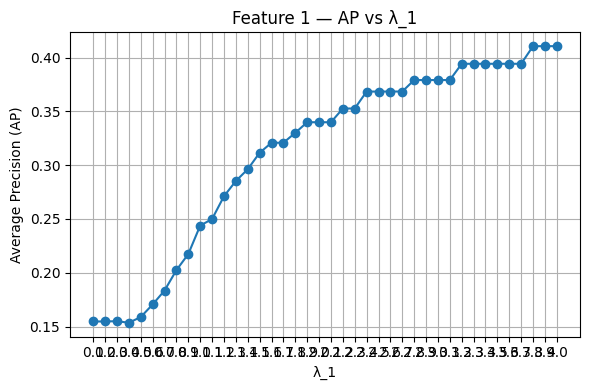

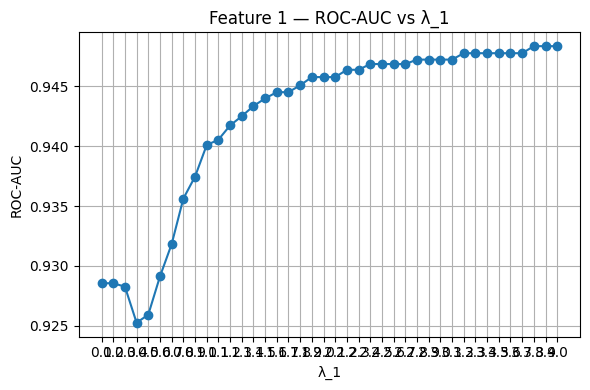

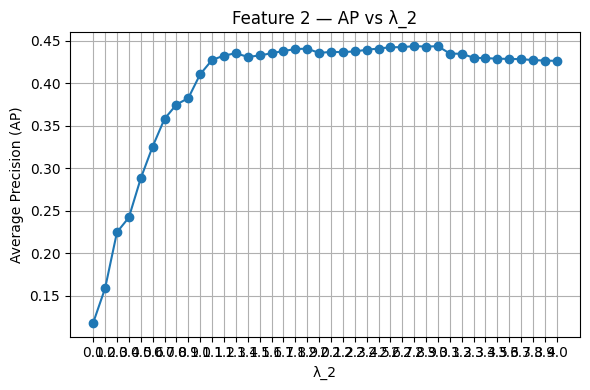

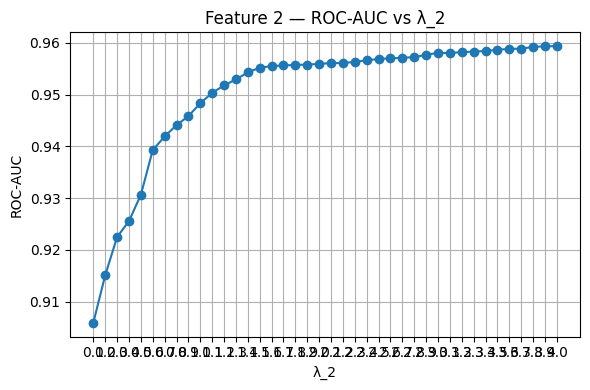

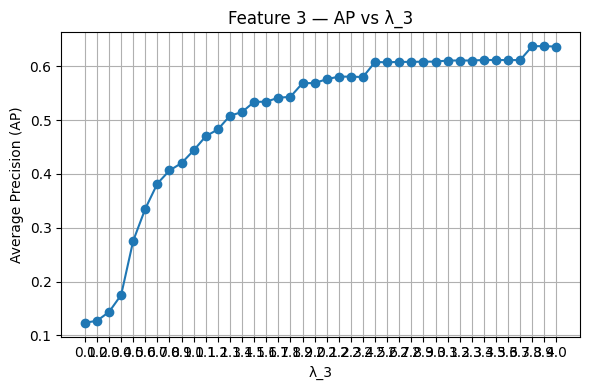

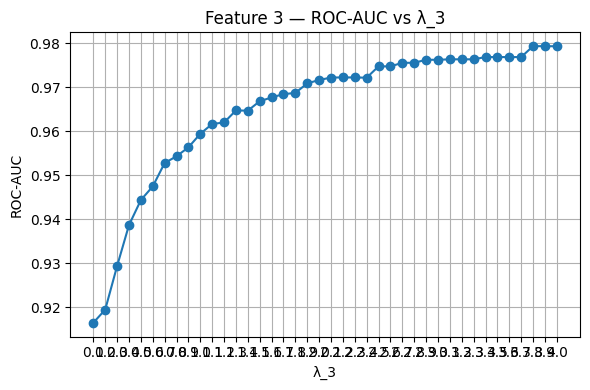

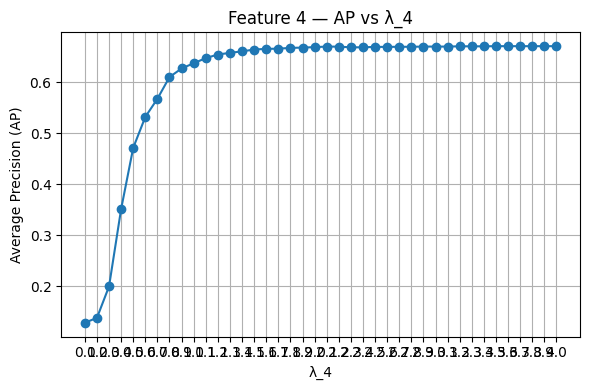

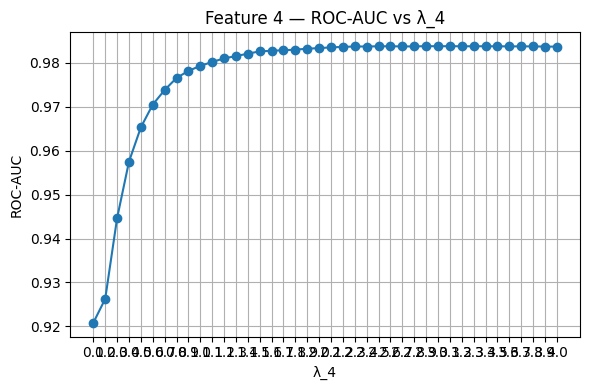

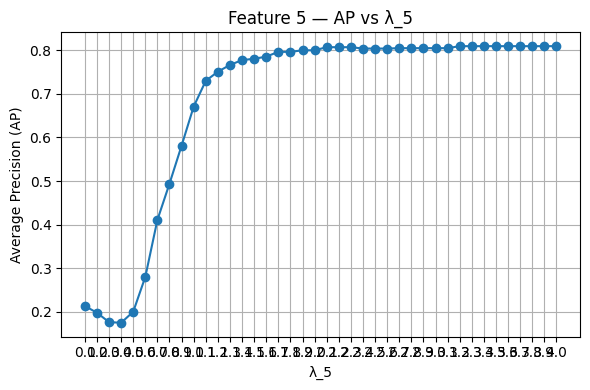

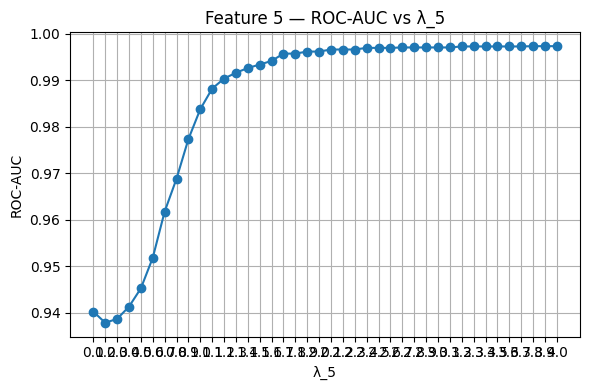

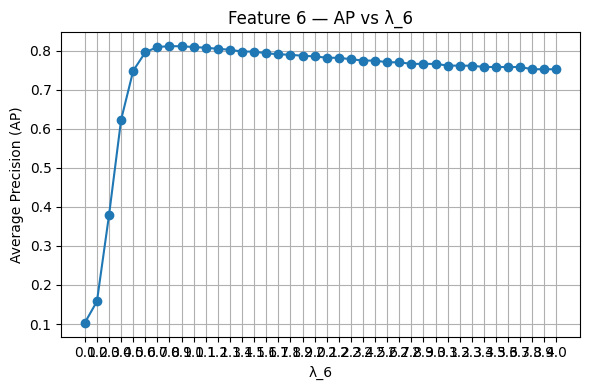

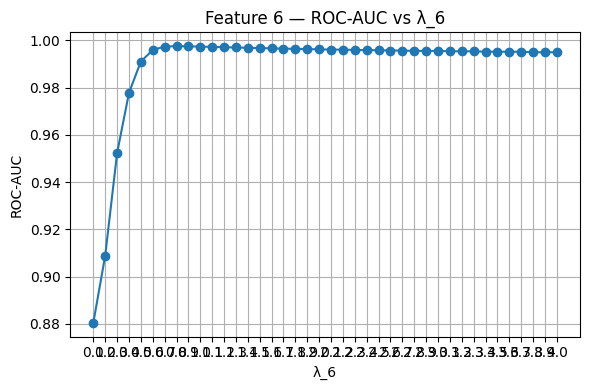

In [36]:
if __name__ == "__main__":
    # =======================
    #1) Setting the parameters
     # =======================
    candidates = [0.1, 0.2, 0.3, 0.4, 0.5,
                  0.6, 0.7, 0.8, 0.9, 1.0,
                  1.1, 1.2, 1.3, 1.4, 1.5,
                  1.6, 1.7, 1.8, 1.9, 2.0,
                  2.1, 2.2, 2.3, 2.4, 2.5,
                  2.6, 2.7, 2.8, 2.9, 3.0,
                  3.1, 3.2, 3.3, 3.4, 3.5,
                  3.6, 3.7, 3.8, 3.9, 4.0]
    # List of candidate values for λ

    # =======================
    #2) Loading and Preprocessing
    # =======================
    mat = loadmat('thyroid.mat')
    full_data = mat['trandata']       # shape = (n_samples, 7)
    X11 = full_data[:, :6]                   # First 6 columns
    y11 =  full_data[:, 6].astype(int)       # Column 7 (index 6)

    # 3) Normalize only the features
    scaler = MinMaxScaler()
    # بردار ستون‌های عددی را جدا می‌کنیم و نرمال می‌کنیم
    X11[:, 1:] = scaler.fit_transform(X11[:, 1:])

    # ================================
    #4) Greedy search for AP
    # ================================
    best_lams_ap, metrics_ap = greedy_search_lambdas(
        X11, y11, X_tem1, candidates, metric_name='AP'
    )
    print("=== Best Lambdas for AP for t1 ===")
    print(best_lams_ap)

    # ================================
    #5) Greedy search for ROC-AUC
    # ================================
    best_lams_roc, metrics_roc = greedy_search_lambdas(
        X11, y11, X_tem1, candidates, metric_name='ROC'
    )
    print("=== Best Lambdas for ROC-AUC for t1 ===")
    print(best_lams_roc)

    # ============================================
    #6) Draw graphs for each feature and each criterion
    # ============================================
    m = X11.shape[1]
    for j in range(m):
        # Chart for AP
        plt.figure(figsize=(6, 4))
        plt.plot(candidates, metrics_ap[j, :], marker='o', linestyle='-')
        plt.title(f"Feature {j+1} — AP vs λ_{j+1}")
        plt.xlabel(f"λ_{j+1}")
        plt.ylabel("Average Precision (AP)")
        plt.grid(True)
        plt.xticks(candidates)
        plt.tight_layout()
        plt.show()

        # Chart for ROC-AUC
        plt.figure(figsize=(6, 4))
        plt.plot(candidates, metrics_roc[j, :], marker='o', linestyle='-')
        plt.title(f"Feature {j+1} — ROC-AUC vs λ_{j+1}")
        plt.xlabel(f"λ_{j+1}")
        plt.ylabel("ROC-AUC")
        plt.grid(True)
        plt.xticks(candidates)
        plt.tight_layout()
        plt.show()

# 🔵 New Approach for t2

### 2. runing algo

In [ ]:
# Conver t2_indices to python list
X_tem2 = t2_indices.tolist()

In [ ]:
# this is for best lammda list for TOP AP & TOP ROC-AUC
if __name__ == "__main__":
    lammda = [2.0, 2.0, 2.0, 2.0, 2.0, 2.0]

    # 1) Load data
    mat       = loadmat('thyroid.mat')
    full_data = mat['trandata']            # shape = (n_samples, 7)

    # 2) Separate features and labels
    X22 = full_data[:, :6]                   # First 6 columns
    y22 =  full_data[:, 6].astype(int)       # Column 7 (index 6)

    # 3) Normalize only the features
    scaler = MinMaxScaler()
    # بردار ستون‌های عددی را جدا می‌کنیم و نرمال می‌کنیم
    X22[:, 1:] = scaler.fit_transform(X22[:, 1:])

    # 4) Run the algorithm with the same X_tem and lammda
    out_scores22 = NEW_WNCROD(X22, X_tem2, lammda)

    # 5) Extract true labels only for X_tem
    y_true22 = y22[X_tem2]

    # 6) Compute metrics
    roc_auc22 = roc_auc_score(y_true22, out_scores22)
    ap22      = average_precision_score(y_true22, out_scores22)

    print(f"ROC-AUC: {roc_auc22:.4f}")
    print(f"Average Precision (AP): {ap22:.4f}")

ROC-AUC: 0.9899
Average Precision (AP): 0.6190


### 3. Greedy Search fo lammda's **(1 Candidate List)**

In [ ]:
def greedy_search_lambdas2(X: np.ndarray,
                          y: np.ndarray,
                          X_tem: list[int],
                          candidates: list[float],
                          metric_name2: str = 'AP'):

    m = X22.shape[1]
    # Start with all λ's equal to 1
    best_lambdas = np.ones(m, dtype=float)
    metric_matrix = np.zeros((m, len(candidates)), dtype=float)
    y_true = y[X_tem2]

    # Selecting the criterion function
    if metric_name2.upper() == 'AP':
        metric_func = average_precision_score
    elif metric_name2.upper() == 'ROC':
        metric_func = roc_auc_score
    else:
        raise ValueError("metric_name2 must be 'AP' or 'ROC'")

    # Loop over each feature
    for j in range(m):
        best_val = -np.inf
        best_c = best_lambdas[j]
        for idx_c, c in enumerate(candidates):
            # Set λ_j = c and other λs constant
            best_lambdas[j] = c
            # Calculate output score
            scores = NEW_WNCROD(X, X_tem, best_lambdas)
            # Calculation of criteria
            val = metric_func(y_true, scores)
            metric_matrix[j, idx_c] = val
            if val > best_val:
                best_val = val
                best_c = c
        # After testing all candidates for feature j, fix λ_j on the best value
        best_lambdas[j] = best_c

    return best_lambdas, metric_matrix

=== Best Lambdas for AP ===
[0.1 0.4 0.1 0.1 0.3 0.1 0.1 0.6 0.1 0.1 0.4 0.1 0.6 0.1 0.1 0.6 0.1 0.4
 0.1 0.1]
=== Best Lambdas for ROC-AUC ===
[0.1 0.4 0.1 0.1 0.3 0.1 0.1 0.6 0.1 0.1 0.4 0.1 0.6 0.1 0.1 0.6 0.1 0.4
 0.1 0.1]


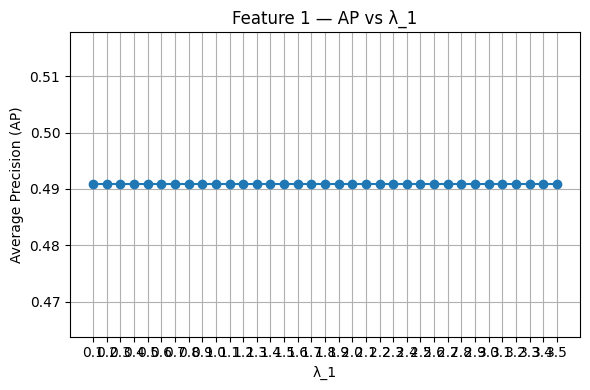

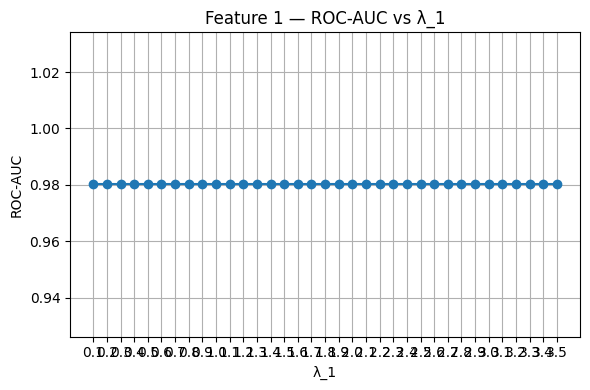

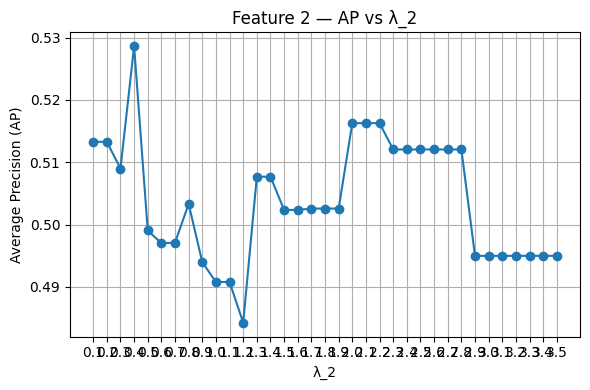

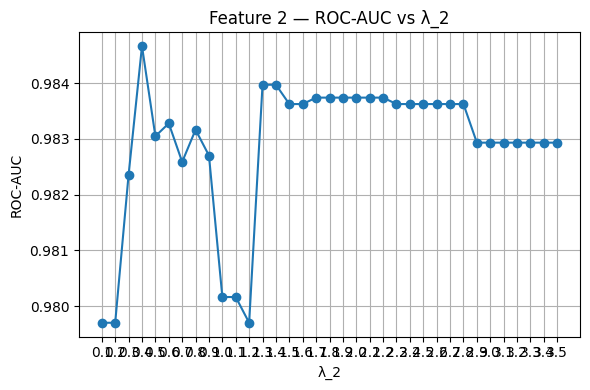

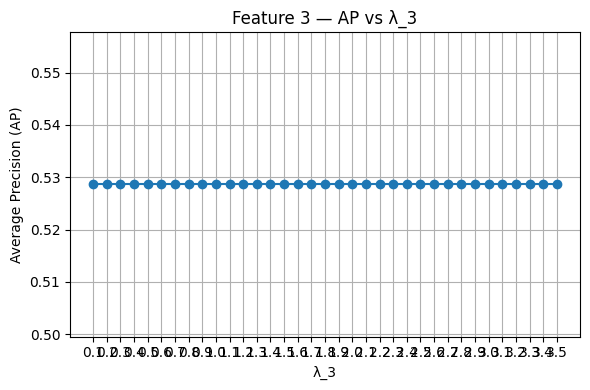

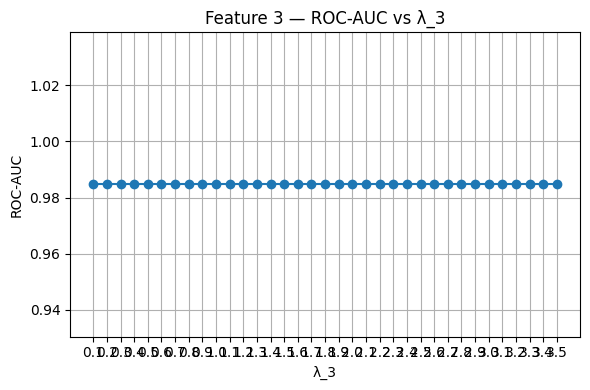

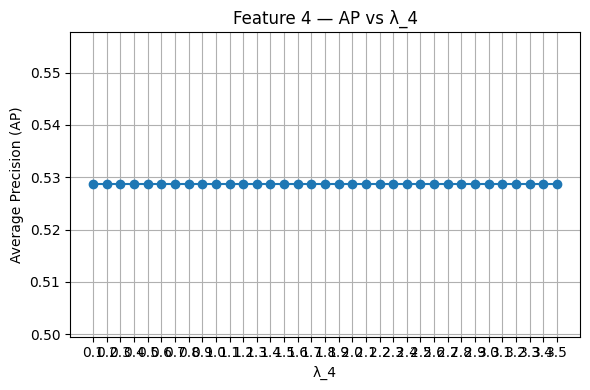

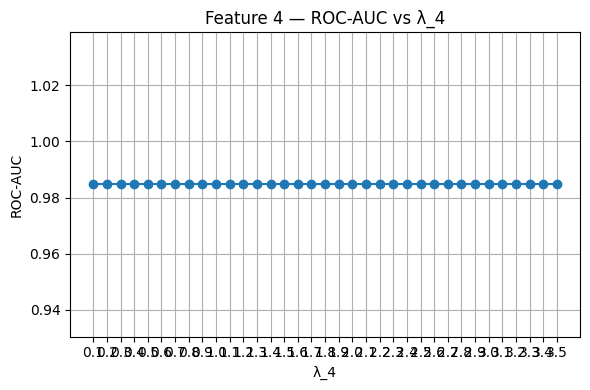

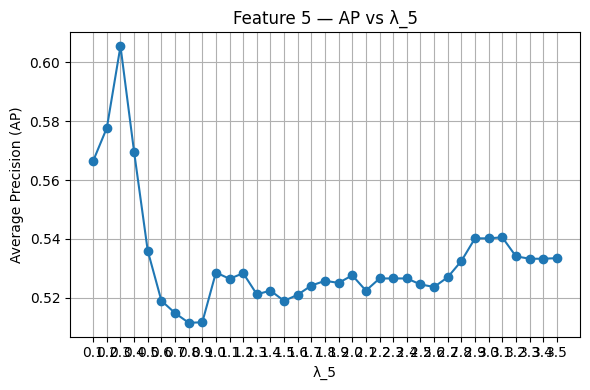

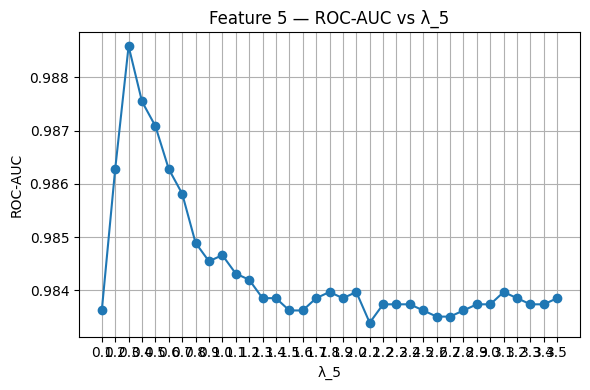

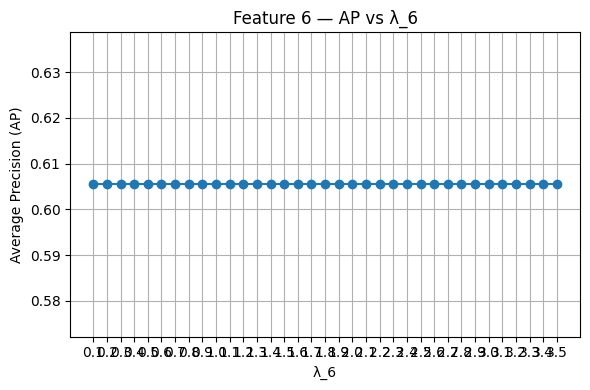

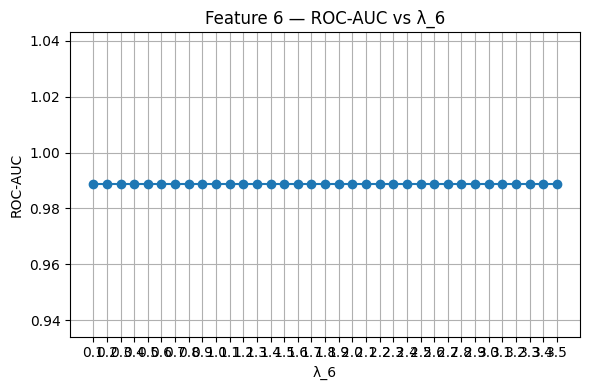

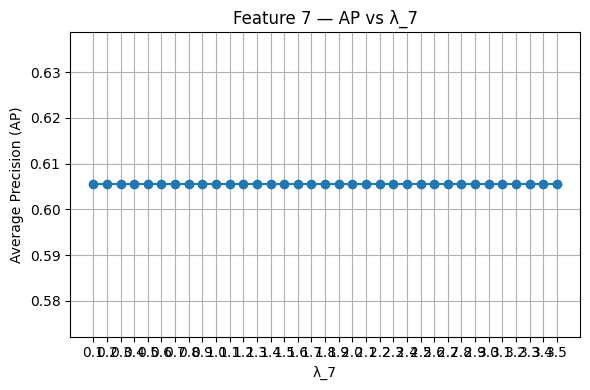

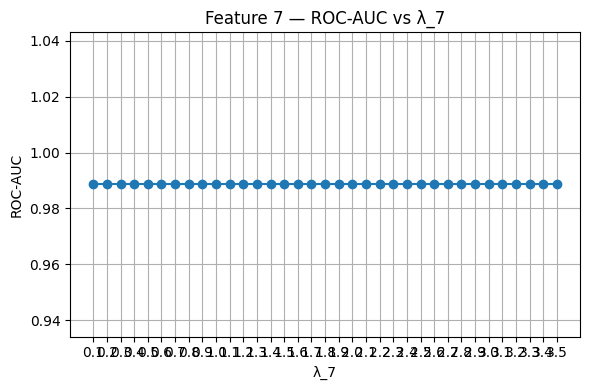

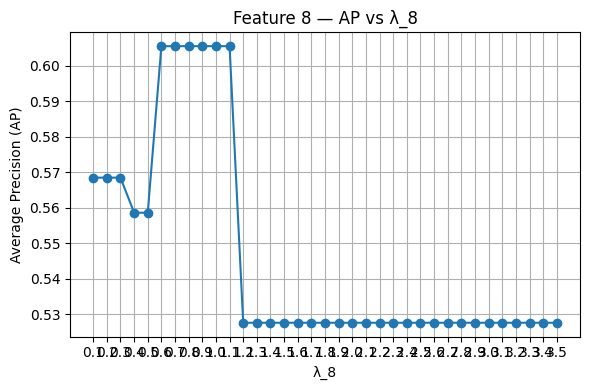

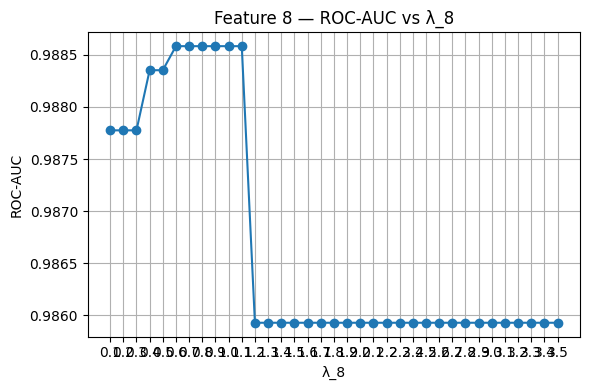

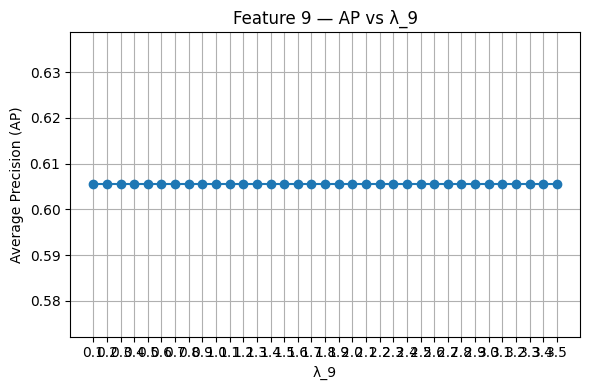

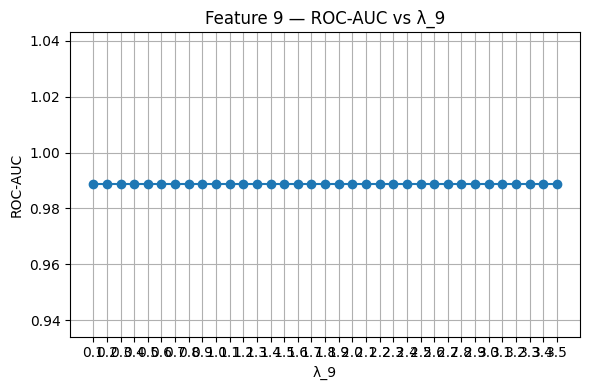

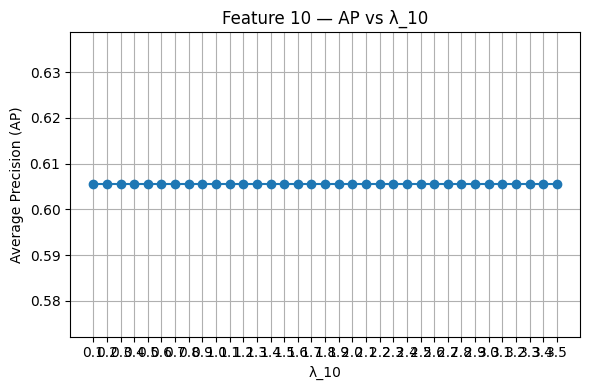

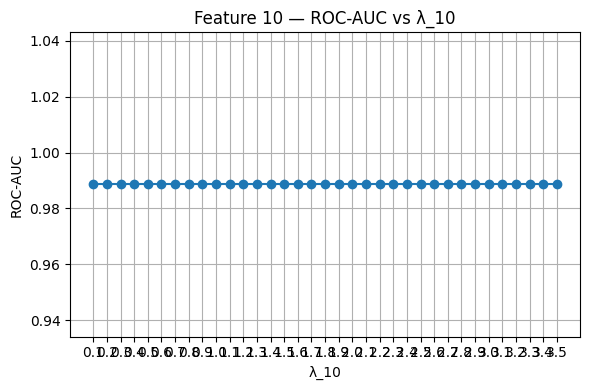

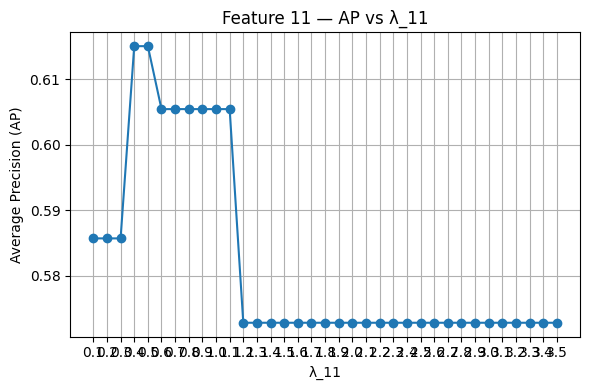

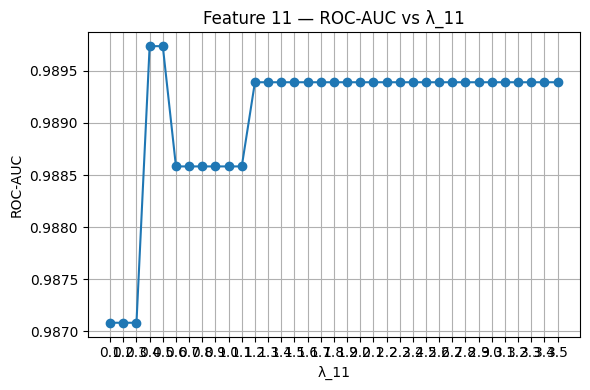

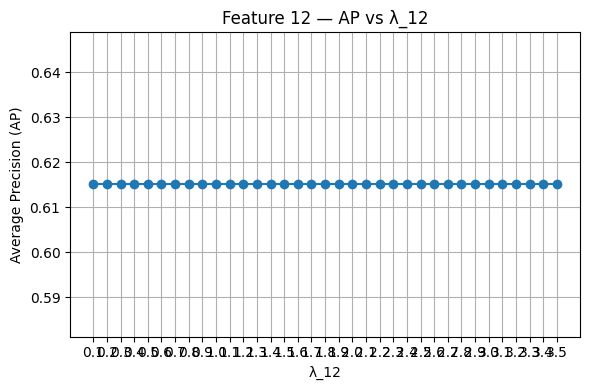

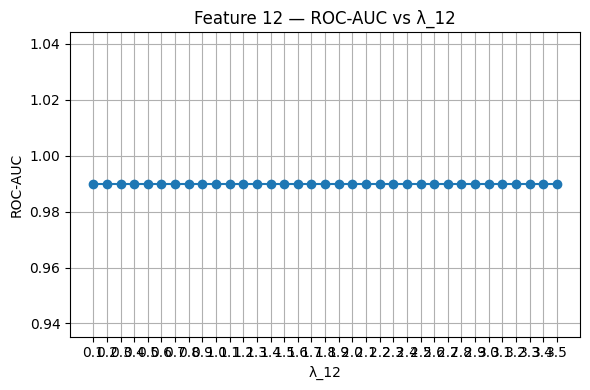

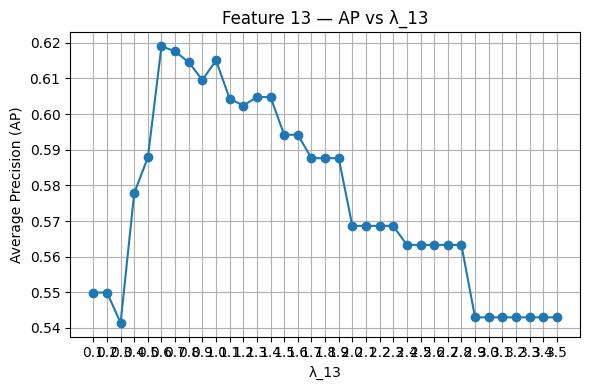

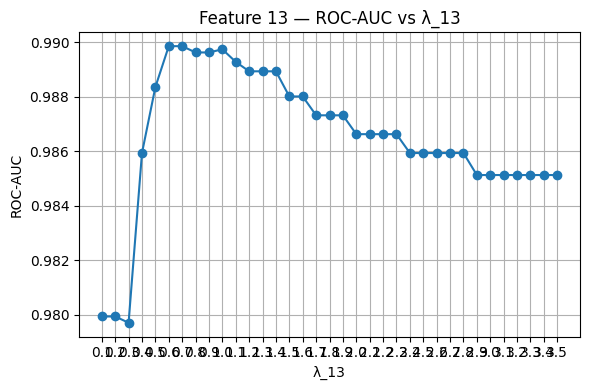

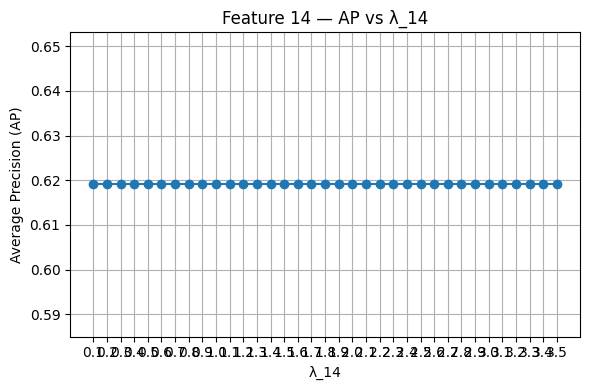

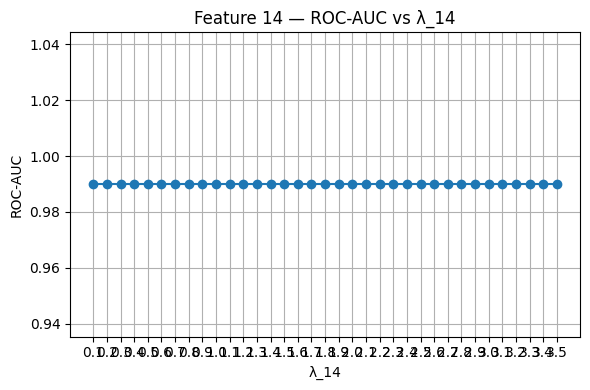

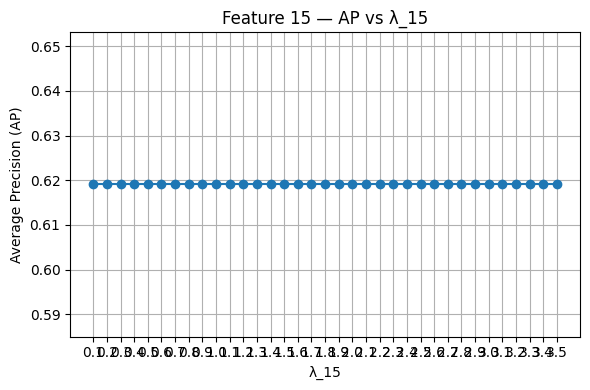

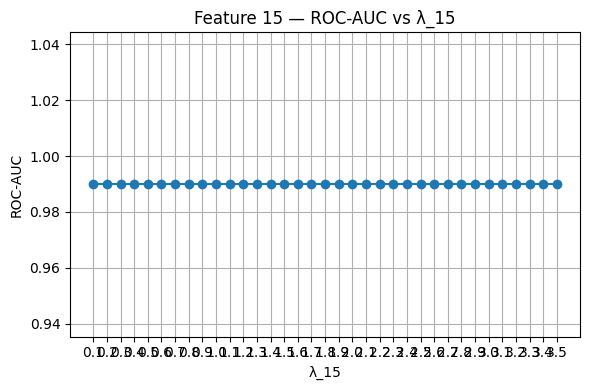

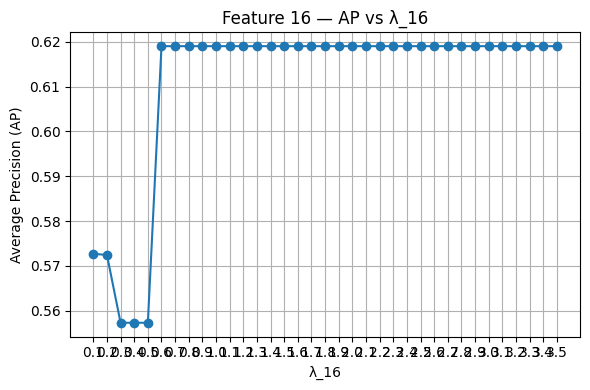

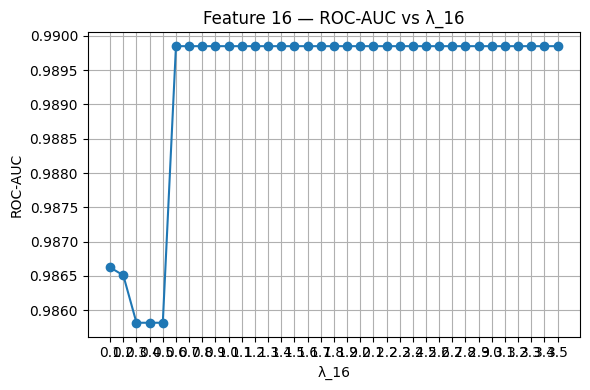

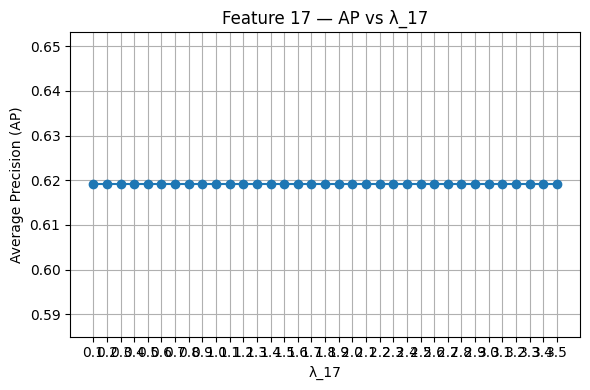

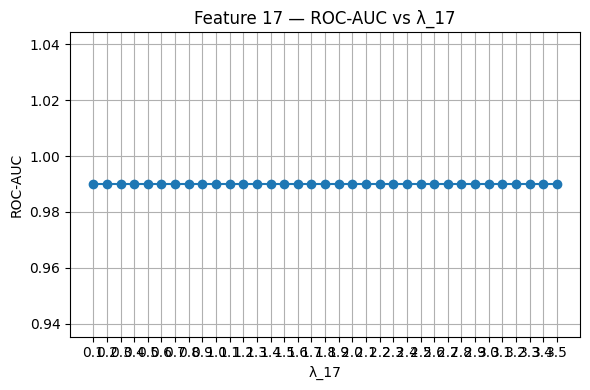

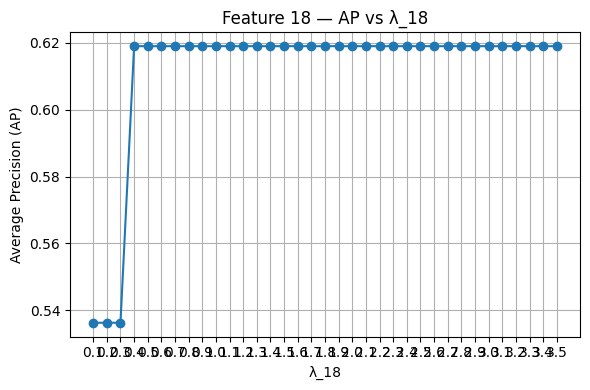

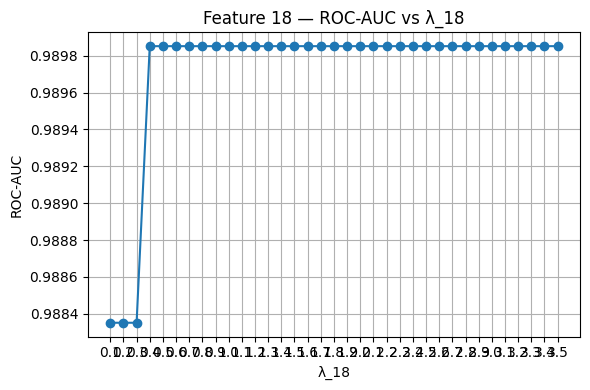

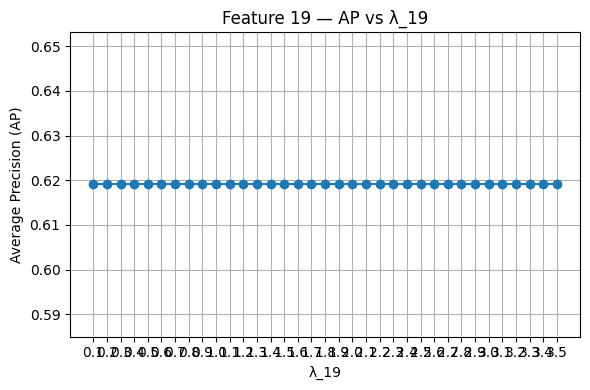

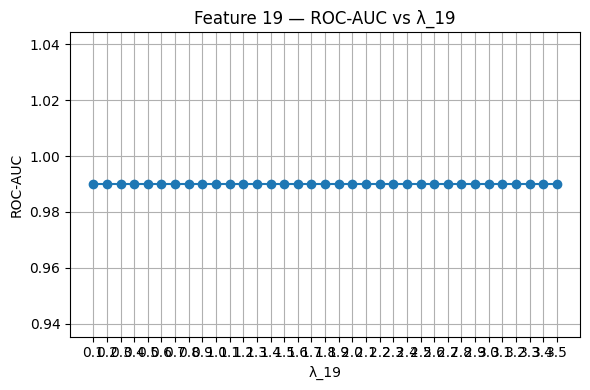

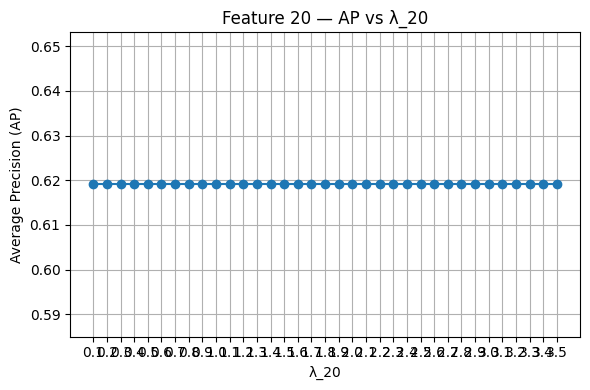

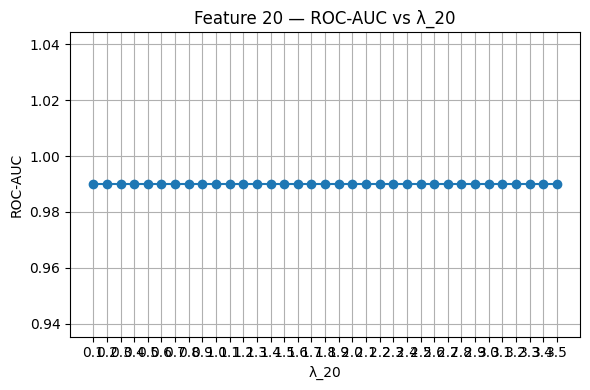

In [ ]:
if __name__ == "__main__":
    # =======================
    #1) Setting the parameters
     # =======================

    candidates = [0.1, 0.2, 0.3, 0.4, 0.5,
                  0.6, 0.7, 0.8, 0.9, 1.0,
                  1.1, 1.2, 1.3, 1.4, 1.5,
                  1.6, 1.7, 1.8, 1.9, 2.0,
                  2.1, 2.2, 2.3, 2.4, 2.5,
                  2.6, 2.7, 2.8, 2.9, 3.0,
                  3.1, 3.2, 3.3, 3.4, 3.5]
    # List of candidate values for λ

    # =======================
    #2) Loading and Preprocessing
    # =======================
    mat = loadmat('german_1_14_variant1.mat')
    full_data = mat['trandata']       # shape = (n_samples, 7)
    X22 = full_data[:, :20]                   # First 20 columns
    y22 =  full_data[:, 20].astype(int)       # Column 21 (index 20)

    numeric_idx = [1, 4, 7, 10, 12, 15, 17]
    scaler = MinMaxScaler()
    # بردار ستون‌های عددی را جدا می‌کنیم و نرمال می‌کنیم
    X22[:, numeric_idx] = scaler.fit_transform(X22[:, numeric_idx])

    # ================================
    #3) Greedy search for AP
    # ================================
    best_lams_ap, metrics_ap = greedy_search_lambdas2(
        X22, y22, X_tem2, candidates, metric_name2='AP'
    )
    print("=== Best Lambdas for AP ===")
    print(best_lams_ap)

    # ================================
    #4) Greedy search for ROC-AUC
    # ================================
    best_lams_roc, metrics_roc = greedy_search_lambdas2(
        X22, y22, X_tem2, candidates, metric_name2='ROC'
    )
    print("=== Best Lambdas for ROC-AUC ===")
    print(best_lams_roc)

    # ============================================
    #5) Draw graphs for each feature and each criterion
    # ============================================
    m = X22.shape[1]
    for j in range(m):
        # Chart for AP
        plt.figure(figsize=(6, 4))
        plt.plot(candidates, metrics_ap[j, :], marker='o', linestyle='-')
        plt.title(f"Feature {j+1} — AP vs λ_{j+1}")
        plt.xlabel(f"λ_{j+1}")
        plt.ylabel("Average Precision (AP)")
        plt.grid(True)
        plt.xticks(candidates)
        plt.tight_layout()
        plt.show()

        # Chart for ROC-AUC
        plt.figure(figsize=(6, 4))
        plt.plot(candidates, metrics_roc[j, :], marker='o', linestyle='-')
        plt.title(f"Feature {j+1} — ROC-AUC vs λ_{j+1}")
        plt.xlabel(f"λ_{j+1}")
        plt.ylabel("ROC-AUC")
        plt.grid(True)
        plt.xticks(candidates)
        plt.tight_layout()
        plt.show()

# 🔵 New Approach for t3

### 2. runing algo

In [39]:
# Conver t3_indices to python list
X_tem3 = t3_indices.tolist()

In [42]:
# this is for best lammda list for TOP AP
if __name__ == "__main__":

    # 1) Load data
    mat       = loadmat('thyroid.mat')
    full_data = mat['trandata']            # shape = (n_samples, 7)

    lammda = [2.0, 2.0, 2.0, 2.0, 2.0, 2.0]

    # 2) Separate features and labels
    X33 = full_data[:, :6]                   # First 6 columns
    y33 =  full_data[:, 6].astype(int)       # Column 7 (index 6)

    # 3) Normalize only the features
    scaler = MinMaxScaler()
    # بردار ستون‌های عددی را جدا می‌کنیم و نرمال می‌کنیم
    X33[:, 1:] = scaler.fit_transform(X33[:, 1:])

    # 4) Run the algorithm with the same X_tem and lammda=
    out_scores33 = NEW_WNCROD(X33, X_tem3, lammda)

    # 5) Extract true labels only for X_tem
    y_true33 = y33[X_tem3]

    # 6) Compute metrics
    roc_auc33 = roc_auc_score(y_true33, out_scores33)
    ap33      = average_precision_score(y_true33, out_scores33)

    print(f"ROC-AUC: {roc_auc33:.4f}")
    print(f"Average Precision (AP): {ap33:.4f}")

ROC-AUC: 0.9924
Average Precision (AP): 0.8518


In [ ]:
# this is for best lammda list for TOP ROC
# this is for best lammda list for TOP AP
if __name__ == "__main__":

    # 1) Load data
    mat       = loadmat('thyroid.mat')
    full_data = mat['trandata']            # shape = (n_samples, 7)

    lammda = [2.0, 2.0, 2.0, 2.0, 2.0, 2.0]

    # 2) Separate features and labels
    X33 = full_data[:, :6]                   # First 6 columns
    y33 =  full_data[:, 6].astype(int)       # Column 7 (index 6)

    # 3) Normalize only the features
    scaler = MinMaxScaler()
    # بردار ستون‌های عددی را جدا می‌کنیم و نرمال می‌کنیم
    X33[:, 1:] = scaler.fit_transform(X33[:, 1:])

    # 4) Run the algorithm with the same X_tem and lammda=
    out_scores33 = NEW_WNCROD(X33, X_tem3, lammda)

    # 5) Extract true labels only for X_tem
    y_true33 = y33[X_tem3]

    # 6) Compute metrics
    roc_auc33 = roc_auc_score(y_true33, out_scores33)
    ap33      = average_precision_score(y_true33, out_scores33)

    print(f"ROC-AUC: {roc_auc33:.4f}")
    print(f"Average Precision (AP): {ap33:.4f}")

ROC-AUC: 0.9983
Average Precision (AP): 0.6792


### 3. Greedy Search fo lammda's **(1 Candidate List)**

In [43]:
def greedy_search_lambdas3(X33: np.ndarray,
                          y33: np.ndarray,
                          X_tem3: list[int],
                          candidates: list[float],
                          metric_name3: str = 'AP'):

    m = X33.shape[1]
    # Start with all λ's equal to 1
    best_lambdas = np.ones(m, dtype=float)
    metric_matrix = np.zeros((m, len(candidates)), dtype=float)
    y_true3 = y33[X_tem3]

    # Selecting the criterion function
    if metric_name3.upper() == 'AP':
        metric_func = average_precision_score
    elif metric_name3.upper() == 'ROC':
        metric_func = roc_auc_score
    else:
        raise ValueError("metric_name3 must be 'AP' or 'ROC'")

    # Loop over each feature
    for j in range(m):
        best_val = -np.inf
        best_c = best_lambdas[j]
        for idx_c, c in enumerate(candidates):
            # Set λ_j = c and other λs constant
            best_lambdas[j] = c
            # Calculate output score
            scores = NEW_WNCROD(X33, X_tem3, best_lambdas)
            # Calculation of criteria
            val = metric_func(y_true3, scores)
            metric_matrix[j, idx_c] = val
            if val > best_val:
                best_val = val
                best_c = c
        # After testing all candidates for feature j, fix λ_j on the best value
        best_lambdas[j] = best_c

    return best_lambdas, metric_matrix

In [ ]:
if __name__ == "__main__":
    # =======================
    #1) Setting the parameters
    # =======================
    # List of candidate values for λ
    candidates = [0.1, 0.2, 0.3, 0.4, 0.5,
                  0.6, 0.7, 0.8, 0.9, 1.0,
                  1.1, 1.2, 1.3, 1.4, 1.5,
                  1.6, 1.7, 1.8, 1.9, 2.0,
                  2.1, 2.2, 2.3, 2.4, 2.5,
                  2.6, 2.7, 2.8, 2.9, 3.0,
                  3.1, 3.2, 3.3, 3.4, 3.5,
                  3.6, 3.7, 3.8, 3.9, 4.0,
                  4.1, 4.2, 4.3, 4.4, 4.5,
                  4.6, 4.7, 4.8, 4.9, 5.0]

    # =======================
    #2) Loading and Preprocessing
    # =======================
    mat = loadmat('thyroid.mat')
    full_data = mat['trandata']       # shape = (n_samples, 7)
    X33 = full_data[:, :6]                   # First 6 columns
    y33 =  full_data[:, 6].astype(int)       # Column 7 (index 6)

    scaler = MinMaxScaler()
    # بردار ستون‌های عددی را جدا می‌کنیم و نرمال می‌کنیم
    X33[:, 1:] = scaler.fit_transform(X33[:, 1:])

    # ================================
    #3) Greedy search for AP
    # ================================
    best_lams_ap, metrics_ap = greedy_search_lambdas3(
        X33, y33, X_tem3, candidates, metric_name3='AP'
    )
    print("=== Best Lambdas for AP ===")
    print(best_lams_ap)

    # ================================
    #4) Greedy search for ROC-AUC
    # ================================
    best_lams_roc, metrics_roc = greedy_search_lambdas3(
        X33, y33, X_tem3, candidates, metric_name3='ROC'
    )
    print("=== Best Lambdas for ROC-AUC ===")
    print(best_lams_roc)

    # ============================================
    #5) Draw graphs for each feature and each criterion
    # ============================================
    m = X33.shape[1]
    for j in range(m):
        # Chart for AP
        plt.figure(figsize=(6, 4))
        plt.plot(candidates, metrics_ap[j, :], marker='o', linestyle='-')
        plt.title(f"Feature {j+1} — AP vs λ_{j+1}")
        plt.xlabel(f"λ_{j+1}")
        plt.ylabel("Average Precision (AP)")
        plt.grid(True)
        plt.xticks(candidates)
        plt.tight_layout()
        plt.show()

        # Chart for ROC-AUC
        plt.figure(figsize=(6, 4))
        plt.plot(candidates, metrics_roc[j, :], marker='o', linestyle='-')
        plt.title(f"Feature {j+1} — ROC-AUC vs λ_{j+1}")
        plt.xlabel(f"λ_{j+1}")
        plt.ylabel("ROC-AUC")
        plt.grid(True)
        plt.xticks(candidates)
        plt.tight_layout()
        plt.show()